<a href="https://colab.research.google.com/github/anrghv/HEP-Tutorial/blob/main/XGB-tut-Hgg.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Machine Learning Tutorial: Classifier Training on ROOT Data

Welcome to this step-by-step walkthrough guide! In this tutorial, I will use Python and PyROOT to load particle physics data, structure it, split it into training and testing partitions using event identification to avoid leakage, train an XGBoost classifier, and thoroughly evaluate its performance.

In [1]:

!pip install ROOT

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 247.9/247.9 MB 17.0 MB/s  0:00:14


### Installing System Dependencies
We first install ROOT (PyROOT) which is crucial for handling experimental physics data formats (`.root` files) within Python.

## 1. Imports and Library Setup
We will start by importing the required libraries, including ROOT (via PyROOT) and NumPy.

In [2]:
import ROOT
import numpy as np

/usr/local/lib/python3.13/dist-packages/ROOT/__init__.py:222: UserWarning: 
This distribution of ROOT is in alpha stage. Feedback is welcome and appreciated. Feel free to reach out to the user forum for questions and general feedback at https://root-forum.cern.ch or to submit an issue at https://github.com/root-project/root/issues. Do not rely on this distribution for production purposes.

  warnings.warn(


### Loading Data via RDataFrame
Now, we create a ROOT RDataFrame targeting the `Events` tree in our signal dataset (`ZHgg.root`). This sets up a lazy-evaluated reference to our dataset.

In [3]:
df_sig = ROOT.RDataFrame("Events","ZHgg.root")


Warning in <TClass::Init>: no dictionary for class edm::Hash<1> is available
Warning in <TClass::Init>: no dictionary for class edm::ProcessHistory is available
Warning in <TClass::Init>: no dictionary for class edm::ProcessConfiguration is available
Warning in <TClass::Init>: no dictionary for class edm::ParameterSetBlob is available
Warning in <TClass::Init>: no dictionary for class pair<edm::Hash<1>,edm::ParameterSetBlob> is available


## 2. Examining the Data Structure
Let's inspect the available column names and determine the feature branches we want to use for training.

In [31]:
columns = df_sig.GetColumnNames()
# columns
print(len(columns))

# for col in columns:
    # if "ev" in col:
      # print(col)

1919


### Feature Branch Selection
We define the specific experimental variables (features) we want to train our model on. Note that we explicitly leave out the raw `event` number as a training feature to prevent the model from learning arbitrary run values.

In [88]:
branches = ["ptll", "detajj", "PuppiMET_pt", "event", "detall"]  #THIS is wrong. never add event in the features branches
# instead
# branches = ["ptll", "detajj", "PuppiMET_pt", "detall"]

In [89]:
# data = df.AsNumpy(["ptll", "detajj"])
data_sig = df_sig.AsNumpy(branches)
# data_all = df.AsNumpy() it will take all the branches in the root files

### Reading the Signal Trees into NumPy arrays
With our target features defined, we export the data from ROOT's internal formats into standard NumPy dictionary-of-arrays using `.AsNumpy()`.

In [90]:
print(type(branches))
print(type(data_sig))
# print(type(data["ptll"]))
# print(len(data["ptll"]))
# print(len(data["detajj"]))

<class 'list'>
<class 'dict'>


In [91]:
print(data_sig['detajj'])

[0.62646484 0.33974314 0.4074707  ... 1.27160645 0.50341797 0.32641602]


In [92]:
# data is a dictionary with a structure like
# data = {
#     "ptll":   ndarray([...]),
#     "detajj": ndarray([...])
# }
print(data_sig.keys())

dict_keys(['ptll', 'detajj', 'PuppiMET_pt', 'event', 'detall'])


## 3. Preparing the Signal Matrix ($X_{\text{sig}}$)
Now, we will convert the signal dictionary into a matrix $X$. We will use `np.column_stack()` to stack the column vectors horizontally.

In [93]:
X_sig = np.column_stack((data_sig["ptll"], data_sig["detajj"], data_sig["PuppiMET_pt"], data_sig["detall"]))
# X_sig = np.column_stack(list(data_sig.values()))
print("The type of the X is ",type(X_sig))
print("The shape ", X_sig.shape)

The type of the X is  <class 'numpy.ndarray'>
The shape  (4525, 4)


### Preparing the Background Matrix ($X_{\text{bkg}}$)
Following the exact same strategy, we load our background dataset (`DY.root`), extract the target columns, and structure them into our feature matrices.

In [79]:
X_sig

array([[ 2.06337982e+02,  6.26464844e-01,  9.93958092e+00,
         1.46575928e-01],
       [-9.99900000e+03,  3.39743137e-01,  5.43982658e+01,
        -9.99900000e+03],
       [ 5.72839928e+01,  4.07470703e-01,  3.58351898e+01,
         1.95261765e+00],
       ...,
       [-9.99900000e+03,  1.27160645e+00,  2.58298550e+01,
        -9.99900000e+03],
       [-9.99900000e+03,  5.03417969e-01,  7.15742159e+00,
        -9.99900000e+03],
       [-9.99900000e+03,  3.26416016e-01,  9.09483719e+01,
        -9.99900000e+03]])

## 4. Preparing the Background Matrix ($X_{\text{bkg}}$)
Similarly, we load and process the background dataset `DY.root` to build $X_{\text{bkg}}$ using the same features.

In [94]:
df_bkg = ROOT.RDataFrame("Events", "DY.root")
# creating dictionary for bkg

data_bkg = df_bkg.AsNumpy(branches)
print(type(data_bkg))
print(data_bkg.keys())

# creating the x_bkg matrix

X_bkg = np.column_stack((data_bkg["ptll"], data_bkg["detajj"], data_bkg["PuppiMET_pt"], data_bkg["detall"]))
# X_bkg = np.column_stack(list(data_bkg.values()))
print(type(X_bkg))
print(X_bkg.shape)

<class 'dict'>
dict_keys(['ptll', 'detajj', 'PuppiMET_pt', 'event', 'detall'])
<class 'numpy.ndarray'>
(51104, 4)


## 5. Label Assignment
Next, we assign target labels $Y$:
* **Signal** ($y_{\text{sig}}$) = $1$
* **Background** ($y_{\text{bkg}}$) = $0$

In [95]:
y_sig = np.ones(len(X_sig))
y_bkg = np.zeros(len(X_bkg))

### Assigning Class Labels
We create our binary classification ground-truth target vectors: `1` for the signal events and `0` for the background events.

In [96]:
print(len(X_sig), len(y_sig))
print(len(X_bkg), len(y_bkg))

4525 4525
51104 51104


In [97]:
# concatanete the two X_* matrices

X = np.concatenate((X_sig, X_bkg), axis=0)
print(X.shape)
X

(55629, 4)


array([[ 2.06337982e+02,  6.26464844e-01,  9.93958092e+00,
         1.46575928e-01],
       [-9.99900000e+03,  3.39743137e-01,  5.43982658e+01,
        -9.99900000e+03],
       [ 5.72839928e+01,  4.07470703e-01,  3.58351898e+01,
         1.95261765e+00],
       ...,
       [ 4.70178986e+01,  7.09521484e+00,  7.56127243e+01,
         8.07373047e-01],
       [ 1.12721605e+01, -9.99900000e+03,  1.40953369e+01,
         9.34814453e-01],
       [ 1.15456095e+01, -9.99900000e+03,  2.47724895e+01,
         1.74804688e+00]])

In [98]:
print(len(y_sig))
print(len(y_bkg))
len(y_sig)+len(y_bkg)

4525
51104


55629

In [99]:
Y = np.concatenate((y_sig, y_bkg), axis=0)
Y

array([1., 1., 1., ..., 0., 0., 0.])

### Splitting Safely with Event Parity
To avoid standard random splitting leakage, we split our data using the parity (even vs. odd) of the unique event ID. This ensures we never split parts of the same physical run context across the boundary.

In [100]:
len(Y)

55629

## 6. Event Identification and Train/Test Splitting
To prevent data leakage, we split the samples using the event ID parity (odd vs. even) rather than a random split.

In [101]:
event_sig = data_sig["event"]
event_bkg = data_bkg["event"]

## Now creating training and testing mask

In [107]:
train_mask_sig = (event_sig %2  == 0)
test_mask_sig = event_sig % 2 != 0
train_mask_bkg = event_bkg %2  == 0
test_mask_bkg = event_bkg %2  != 0

print(train_mask_sig)
print(test_mask_sig)
print(train_mask_bkg)
print(test_mask_bkg)


[False False  True ...  True False  True]
[ True  True False ... False  True False]
[ True False False ...  True  True False]
[False  True  True ... False False  True]


In [108]:
X_sig_train = X_sig[train_mask_sig]
X_sig_test = X_sig[test_mask_sig]

X_bkg_train = X_bkg[train_mask_bkg]
X_bkg_test = X_bkg[test_mask_bkg]

In [117]:
print(X_sig_train.shape[0] + X_sig_test.shape[0])
print(len(X_sig))

4525
4525


## 7. Combining Train and Test Datasets
Now we concatenate the individual signal and background partitions into unified training and testing matrices.

In [118]:
X_train = np.concatenate((X_sig_train, X_bkg_train), axis=0)
X_test = np.concatenate((X_sig_test, X_bkg_test), axis=0)

In [121]:
y_sig_train = np.ones(len(X_sig_train))
y_sig_test = np.ones(len(X_sig_test))
y_bkg_train = np.zeros(len(X_bkg_train))
y_bkg_test = np.zeros(len(X_bkg_test))


y_train = np.concatenate((y_sig_train, y_bkg_train), axis=0)
y_test = np.concatenate((y_sig_test, y_bkg_test), axis=0)

print(y_train.shape)
print(y_test.shape)
print(X_train.shape)
print(X_test.shape)

(27966,)
(27663,)
(27966, 4)
(27663, 4)


### Training our XGBoost Classifier
We initialize an `XGBClassifier` with a maximum depth of 3 and 100 sequential trees to prevent excessive overfitting, then train the model on our combined training matrix.

## 8. Model Training with XGBoost
We initialize and fit an `XGBClassifier` to classify signal versus background events.

In [123]:
from xgboost import XGBClassifier

In [124]:
model = XGBClassifier(n_estimators = 100,
                      max_depth = 3,
                      learning_rate = 0.1)

model.fit(X_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=None, num_parallel_tree=None, ...)

In [146]:
y_test_score = model.predict_proba(X_test)[:,1]
# [:,1] means take the probabilty assigned to class 1, ie signal

In [126]:
X_test.shape

(27663, 4)

In [147]:
len(y_test_score)
print(y_test_score.shape)

(27663,)


## 9. Model Evaluation
Now we collect the predicted classifier probabilities on the test set:
* `y_test`: True ground-truth labels
* `y_test_score`: Classifier's signal scores

### ROC Curve and AUC Evaluation
We evaluate performance by plotting the Receiver Operating Characteristic (ROC) curve and calculating the Area Under the Curve (AUC) for both training and testing datasets.

In [227]:
from sklearn.metrics import roc_auc_score, roc_curve

In [228]:
y_test

array([1., 1., 1., ..., 0., 0., 0.])

In [229]:
y_train_score = model.predict_proba(X_train)[:,1]
print(len(y_train_score))

test_auc = roc_auc_score(y_test, y_test_score)
print(f"Testing auc is {test_auc: .3f}")

train_auc = roc_auc_score(y_train, y_train_score)
print(f"Training auc is {train_auc: .3f}")

print(f"Difference in test and train auc is {abs(train_auc-test_auc):.3f}")

27966
Testing auc is  0.974
Training auc is  0.977
Difference in test and train auc is 0.003


In [238]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr_test, tpr_test, thresholds_test = roc_curve(y_test, y_test_score)
fpr_train, tpr_train, thresholds_train = roc_curve(y_train, y_train_score)

# print(type(fpr))
# print(type(tpr))
# print(type(thresholds))
# print(fpr)
# print(tpr.shape)
# print(thresholds.shape)

### ROC Curve Visual Validation
We visualize the True Positive Rate vs False Positive Rate at different thresholds. An ideal model has a curve that arches high towards the top-left corner (AUC closer to 1.0).

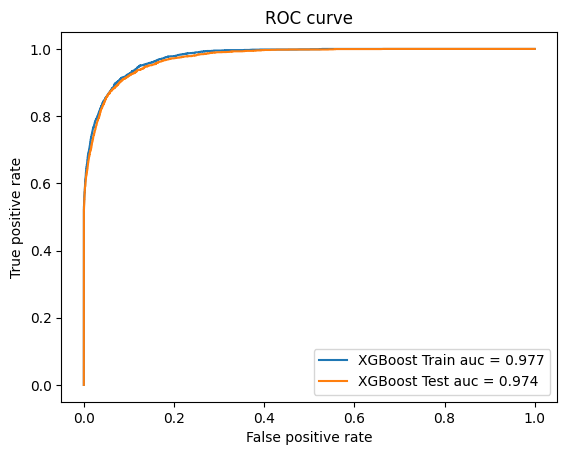

In [239]:
plt.plot(fpr_train,
         tpr_train,
         label= f"XGBoost Train auc = {train_auc:.3f}")
plt.plot(fpr_test,
         tpr_test,
         label= f"XGBoost Test auc = {test_auc:.3f}")

plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve")

plt.legend()

### Classifier Overfitting Check
To evaluate potential overtraining, we will plot the distribution of BDT classifier scores for both signal and background, separated into training and testing sets.

In [162]:
print("y_train =", y_train)
print("y_test =", y_test)
print("y_train_score =", y_train_score)
print("y_test_score =", y_test_score)

y_train = [1. 1. 1. ... 0. 0. 0.]
y_test = [1. 1. 1. ... 0. 0. 0.]
y_train_score = [3.4820592e-01 1.1902662e-01 9.9847776e-01 ... 4.6550289e-02 2.1514434e-02
 5.7488040e-04]
y_test_score = [6.9706899e-01 9.9891782e-01 9.9650782e-01 ... 2.4289191e-03 2.6588351e-04
 1.5364907e-03]


In [171]:
y_train_mask = y_train == 1
sig_train_scores = y_train_score[y_train_mask]
# print(sig_train_scores)

y_train_bkg_mask = y_train == 0
bkg_train_scores = y_train_score[y_train_bkg_mask]
# print(bkg_train_scores)

y_test_sig_mask = y_test ==1  # tells us which test events are signal
y_test_bkg_mask = y_test ==0

sig_test_scores = y_test_score[y_test_sig_mask]
bkg_test_scores = y_test_score[y_test_bkg_mask]


[0.34820592 0.11902662 0.99847776 ... 0.99808097 0.99808097 0.99885154]
[0.00068195 0.01760002 0.02065244 ... 0.04655029 0.02151443 0.00057488]


### Overtraining Diagnostics
We compare the histograms of the training scores against the test scatter points. If the distributions align nicely, it indicates our model generalizes correctly without overtraining.

Now we need to compare

`sig_train_scores`, `bkg_train_scores`
`sig_test_scores`,
`bkg_test_scores`

for overtraining.

For the overtraining plot:
- x-axis: BDT score
- y-axis: number of events (or normalized event density)
- Four distributions: signal/background × train/test.

f there is no significant overtraining, the training and testing BDT-score distributions should be reasonably similar—roughly overlapping for both signal and background.

If they differ strongly, for example the training sample has a much sharper or more extreme distribution than the testing sample, that can indicate overtraining.

In [172]:
import matplotlib.pyplot as plt

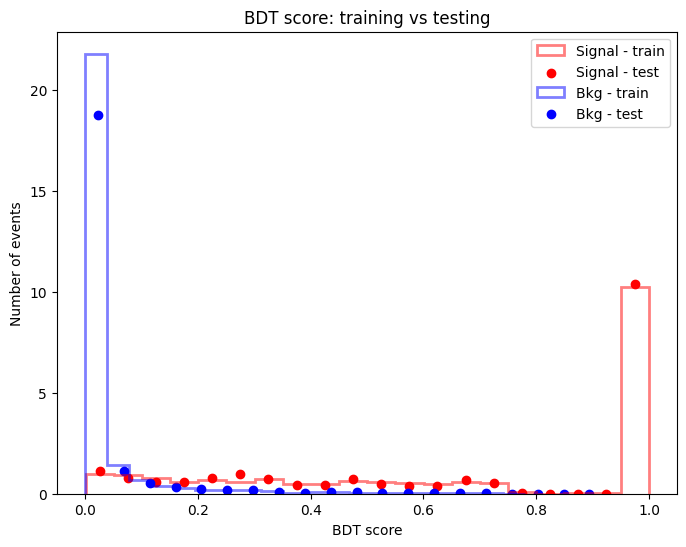

In [240]:
plt.figure(figsize=(8, 6))
plt.hist(sig_train_scores, bins = 20, alpha =0.5,histtype = "step", linewidth = 2, label  = "Signal - train", density = True, color = "r")
counts, bin_edges = np.histogram(sig_test_scores, bins = 20, density = True)
bin_centers = (bin_edges[:-1] + bin_edges[1:])/2
plt.scatter(bin_centers, counts, label = "Signal - test", color = "r")

plt.hist(bkg_train_scores, bins = 20, alpha =0.5,histtype = "step", linewidth = 2, label  = "Bkg - train",density = True, color = "b")
counts, bin_edges = np.histogram(bkg_test_scores, bins = 20, density = True)
bin_centers = (bin_edges[:-1] + bin_edges[1:])/2
plt.scatter(bin_centers, counts, label = "Bkg - test", color = "b")
plt.xlabel("BDT score")
plt.ylabel("Number of events")
plt.title("BDT score: training vs testing")
plt.legend()
plt.show()

## 10. Correlation Analysis
Let's evaluate the linear correlations among our training features.

In [212]:
features = [branch for branch in branches if branch != "event"]
features

['ptll', 'detajj', 'PuppiMET_pt', 'detall']

In [213]:
import pandas as pd


In [215]:
df_features = pd.DataFrame(X_train, columns = features)
corr = df_features.corr()
corr

,ptll,detajj,PuppiMET_pt,detall
ptll,1.000000,-0.194582,-0.248789,0.999875
detajj,-0.194582,1.000000,0.326576,-0.199232
PuppiMET_pt,-0.248789,0.326576,1.000000,-0.251001
detall,0.999875,-0.199232,-0.251001,1.000000


### Correlation Heatmap Visualization

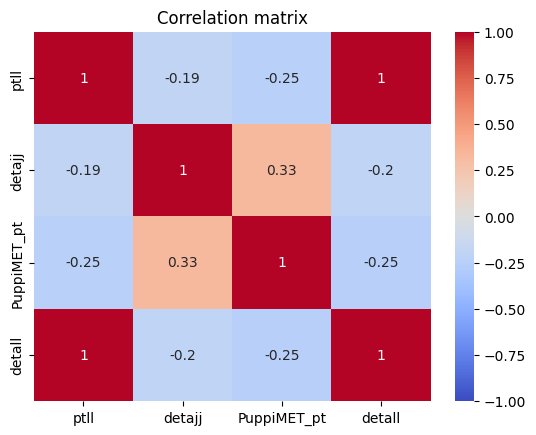

In [216]:
import seaborn as sns

sns.heatmap(corr,
            annot = True,
            cmap = "coolwarm",
            vmin = -1,
            vmax = 1)

plt.title("Correlation matrix")
plt.show()

### Feature Importances
Lastly, we look at the decision weight distribution across our variables to see which physics features drove the classification results most strongly.

## 11. Feature Importance Analysis
Finally, we extract and inspect the relative importance assigned to each feature by the trained XGBoost model.

In [218]:
importance = pd.DataFrame({
    "feature": features,
    "importance": model.feature_importances_
})
importance

,feature,importance
0,ptll,0.435225
1,detajj,0.148051
2,PuppiMET_pt,0.006886
3,detall,0.409839


In [220]:
# Now sort them

importance = importance.sort_values(
    "importance", ascending=False
)

importance

,feature,importance
0,ptll,0.435225
3,detall,0.409839
1,detajj,0.148051
2,PuppiMET_pt,0.006886


### Visualizing Feature Importance

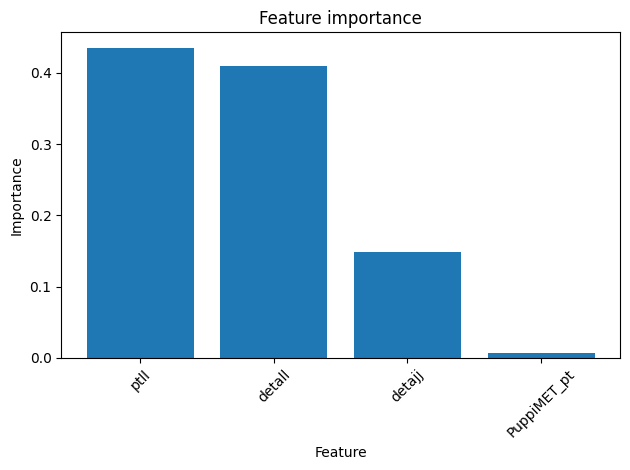

In [224]:
plt.bar(
    importance["feature"],
    importance["importance"],
)

plt.xlabel("Feature")
plt.ylabel("Importance")
plt.title("Feature importance")

plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

In [242]:
!pip install Uproot

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 18.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 698.7/698.7 kB 21.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [Uproot]


In [241]:
import uproot
with uprooot.open("ZHgg.root") as f:
    print(f.keys())

ModuleNotFoundError: No module named 'uproot'